In [3]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [4]:
df = pd.read_csv("emails.csv")

df.head()

X = df.drop(columns = ["Email No.", "Prediction"])
y = df["Prediction"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

knn_model = KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2)
svm_model = SVC(kernel='rbf', C=1.0, random_state = 42)

knn_model.fit(X_train_scaled, y_train)

# 3. Train SVM Model
print("Training Support Vector Machine Classifier...")
svm_model.fit(X_train_scaled, y_train)

# 4. Generate Predictions
knn_preds = knn_model.predict(X_test_scaled)
svm_preds = svm_model.predict(X_test_scaled)

print("Model training and predictions complete!")


Training Support Vector Machine Classifier...
Model training and predictions complete!


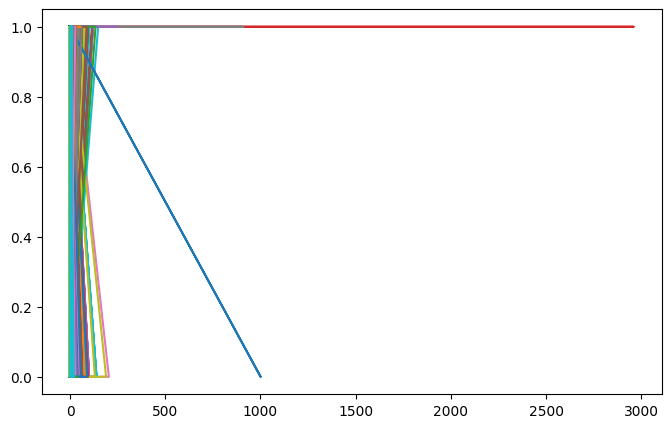

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import seaborn as sns

import matplotlib.pyplot as plt

knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)

knn.fit(X_train_scaled, y_train)
pred = knn.predict(X_test_scaled)

plt.figure(figsize=(8,5))
plt.plot(X_test_scaled,pred)
plt.show()

In [6]:
knn_preds

array([0, 0, 1, ..., 1, 0, 1], shape=(1035,))

In [16]:
svc = SVC(kernel='rbf', C = 1.0, random_state=42)
svc.fit(X_train_scaled, y_train)
svc.predict(X_test_scaled)

array([0, 0, 0, ..., 1, 0, 1], shape=(1035,))

In [7]:
from sklearn.metrics import accuracy_score

svm_score = accuracy_score(y_test, svm_preds)
knn_score = accuracy_score(y_test, knn_preds)

print(svm_score)
print(knn_score)

0.9304347826086956
0.8338164251207729
